# NN_L8_yc_latent_time

**Lecture 8 of Neural Networks and Deep Learning (NN). Latent means of a two-factor VAE of the euro-area AAA yield curve over time, and their correlation with level and slope.**

Neural Networks and Deep Learning (NN), Lecture 8 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L8/NN_L8_yc_latent_time/NN_L8_yc_latent_time.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Correlation of the latent means with the level (mean of 11 yields) and the slope (10Y - 3M).

corr(z2, level) = 0.99   [yc.vae_corr.z2_level]
corr(z1, slope) = 0.66   [yc.vae_corr.z1_slope]


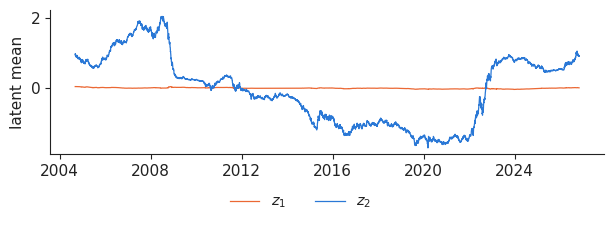

In [3]:
z = pd.read_csv(REPO + 'lectures/L8/results/' + 'yc_vae_latent.csv', parse_dates=['date'])
show('yc.vae_corr.z2_level', 'corr(z2, level)', round(float(np.corrcoef(z.z2, z.level)[0, 1]), 2))
show('yc.vae_corr.z1_slope', 'corr(z1, slope)', round(float(np.corrcoef(z.z1, z.slope)[0, 1]), 2))
fig, ax = plt.subplots(figsize=(6.4, 2.3))
ax.plot(z.date, z.z1, color=PAL['model'], lw=0.9, label='$z_1$')
ax.plot(z.date, z.z2, color=PAL['data'], lw=0.9, label='$z_2$')
ax.set_ylabel('latent mean')
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('yc_latent_time.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()